# Investigación 1 — Carga o lectura de diversos formatos de datos con Pandas

**Universidad Tecnológica de Panamá** — Facultad de Ingeniería de Sistemas Computacionales
Departamento de Sistemas de Información, Control y Evaluación de Recursos Informáticos

**Profesora:**
Gema Castillo


**Integrantes:**
- Ruben Feng
- Juan Morales
- Kevin Linares
- Nohelanys Camaño
- Calvin Miro

| # | Pregunta | Puntos |
|---|----------|-------:|
| 1 | El concepto de DataFrame | 5 |
| 2 | Métodos de lectura y carga (+ todos los archivos del ecampus + web scraping) | 50 |
| 3 | Diversidad de formatos de archivo | 5 |
| 4 | Eficiencia en formatos avanzados (Parquet, ORC, Feather…) | 15 |
| 5 | Automatización de ingesta (ETL) | 5 |
| 6 | Importancia de los fundamentos | 5 |
| 7 | Comparativa Plotly vs. Matplotlib (+ gráficas) | 15 |

**Cómo ejecutar:** en Google Colab, ejecutar *Entorno de ejecución → Ejecutar todas*. La celda de la sección 0 pide subir los archivos del ecampus; en local basta con copiarlos a la carpeta `datos/` junto a este notebook.

## 0. Preparación del entorno
Instalamos (si faltan) las dependencias de I/O: `pyarrow` (Parquet/Feather/ORC), `openpyxl` (Excel), `lxml`/`beautifulsoup4` (HTML/XML) y `plotly`. Colab ya trae casi todas.

In [25]:
%pip install -q pandas pyarrow openpyxl lxml beautifulsoup4 plotly requests

In [26]:
import os, io, csv, json, time, sqlite3, logging, platform
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

DATA_DIR = Path("datos")            # archivos del ecampus
GEN_DIR = Path("datos_generados")   # archivos que genera este notebook
DATA_DIR.mkdir(exist_ok=True)
GEN_DIR.mkdir(exist_ok=True)

COLOR = "#2a6f97"  # un solo tono: todas las gráficas muestran una sola serie
pd.set_option("display.max_columns", 30)
print("pandas", pd.__version__, "| Python", platform.python_version(), "|", platform.system())

pandas 2.2.3 | Python 3.13.18 | Linux


### 0.1 Subir los archivos del ecampus
En Colab se abre el selector de archivos; se pueden seleccionar **todos** a la vez. En local la celda solo lista lo que haya en `datos/`.

In [27]:
# try:
#     from google.colab import files
#     for nombre, contenido in files.upload().items():
#         (DATA_DIR / nombre).write_bytes(contenido)
# except ImportError:
#     print("Entorno local: copie los archivos del ecampus en", DATA_DIR.resolve())

# print(sorted(p.name for p in DATA_DIR.iterdir()))

## 1. El concepto de DataFrame (5 pts)

**Definición formal.** Un `pandas.DataFrame` es una estructura de datos **bidimensional, tabular, mutable en tamaño y potencialmente heterogénea**, compuesta por:

- un **índice de filas** (`Index`) y un **índice de columnas** (`Index`), ambos etiquetados;
- una colección ordenada de **columnas**, donde cada columna es una `Series` (arreglo 1-D **homogéneo** con un `dtype` propio: `int64`, `float64`, `datetime64`, `category`, `string`, `bool`, …).

Formalmente puede verse como un diccionario ordenado `{etiqueta_columna: Series}` en el que todas las Series comparten el mismo índice de filas (alineación por etiquetas). Internamente las columnas se almacenan como arreglos contiguos de NumPy/Arrow (almacenamiento **columnar**).

**Ventajas arquitectónicas frente a estructuras nativas y arreglos multidimensionales:**

| Aspecto | Lista de diccionarios (Python) | `numpy.ndarray` 2-D | `DataFrame` |
|---|---|---|---|
| Disposición en memoria | Objetos Python dispersos (un `dict` por fila, claves repetidas) | Bloque contiguo, **un único dtype** | Columnar: un arreglo contiguo **por columna**, cada uno con su dtype |
| Tipos heterogéneos | Sí, pero sin control | No (todo se vuelve `object` o `float`) | Sí, tipado por columna |
| Operaciones | Bucles `for` interpretados | Vectorizadas, pero por posición | **Vectorizadas** (C/NumPy/Arrow) y por **etiqueta** |
| Alineación | Manual | Manual (por posición) | Automática por índice al operar/unir |
| Valores faltantes | `None` ad hoc | Solo `NaN` en floats | `NaN`/`NA`/`NaT` uniformes + `isna`, `fillna`, `dropna` |
| Álgebra relacional | Hay que programarla | No existe | `merge`, `groupby`, `pivot_table`, `melt`, ventanas, series de tiempo |
| E/S | Manual | `loadtxt` limitado | +20 lectores/escritores (`read_*` / `to_*`) |

En resumen: el DataFrame combina el **rendimiento** de los arreglos vectorizados con la **semántica relacional** de una tabla SQL y la **expresividad** de Python. La celda siguiente lo comprueba empíricamente.

In [28]:
n = 200_000
rng = np.random.default_rng(0)
registros = [{"precio": float(p), "cantidad": int(c)} for p, c in zip(rng.uniform(1, 100, n), rng.integers(1, 10, n))]
df_demo = pd.DataFrame(registros)

t0 = time.perf_counter(); total_py = sum(r["precio"] * r["cantidad"] for r in registros); t_py = time.perf_counter() - t0
t0 = time.perf_counter(); total_pd = (df_demo["precio"] * df_demo["cantidad"]).sum(); t_pd = time.perf_counter() - t0
assert np.isclose(total_py, total_pd)

import sys
mem_py = sum(sys.getsizeof(r) + sum(sys.getsizeof(v) for v in r.values()) for r in registros)
mem_pd = df_demo.memory_usage(deep=True).sum()
print(f"Bucle Python : {t_py*1000:8.2f} ms | memoria ≈ {mem_py/1e6:6.1f} MB")
print(f"DataFrame    : {t_pd*1000:8.2f} ms | memoria ≈ {mem_pd/1e6:6.1f} MB")
print(f"→ {t_py/t_pd:.0f}x más rápido y {mem_py/mem_pd:.0f}x menos memoria")

# Heterogeneidad: NumPy fuerza un único dtype, el DataFrame conserva uno por columna
mixto = [("Ana", 25, True), ("Luis", 31, False)]
print("\nnumpy dtype:", np.array(mixto).dtype)
print(pd.DataFrame(mixto, columns=["nombre", "edad", "activo"]).dtypes.to_string())

Bucle Python :   122.73 ms | memoria ≈   47.2 MB
DataFrame    :     4.33 ms | memoria ≈    3.2 MB
→ 28x más rápido y 15x menos memoria

numpy dtype: <U21
nombre    object
edad       int64
activo      bool


## 2. Métodos de lectura y carga (50 pts)

### 2.1 Funciones principales del módulo de E/S de pandas
Todas siguen el patrón `pd.read_<formato>()` para leer y `DataFrame.to_<formato>()` para escribir ([IO tools, pandas 3.0](https://pandas.pydata.org/docs/user_guide/io.html)).

| Tipo | Lectura | Escritura | Uso típico |
|---|---|---|---|
| Texto delimitado | `read_csv`, `read_table`, `read_fwf` | `to_csv` | CSV, TSV, ancho fijo, logs |
| Hoja de cálculo | `read_excel` (motores `openpyxl`, `calamine`, `xlrd`, `odf`) | `to_excel` | `.xlsx`, `.xls`, `.ods` |
| Semiestructurado | `read_json`, `json_normalize`, `read_xml`, `read_html` | `to_json`, `to_xml`, `to_html` | APIs REST, MongoDB, web scraping |
| Bases de datos | `read_sql`, `read_sql_query`, `read_sql_table` | `to_sql` | SQLite, PostgreSQL, MySQL, SQL Server (vía SQLAlchemy/ADBC) |
| Binario columnar | `read_parquet`, `read_orc`, `read_feather` | `to_parquet`, `to_orc`, `to_feather` | Data lakes, intercambio rápido |
| Binario científico/estadístico | `read_hdf`, `read_stata`, `read_sas`, `read_spss`, `read_pickle` | `to_hdf`, `to_stata`, `to_pickle` | Ciencia, encuestas, caché |
| Otros | `read_clipboard`, `read_iceberg` | `to_clipboard`, `to_markdown`, `to_latex` | Prototipado, reportes |

### 2.2 Parámetros críticos

**Problemas de codificación (`encoding`)**
- `encoding="utf-8" | "utf-8-sig" | "latin-1" | "cp1252"`: archivos de Excel/Windows en español suelen venir en `cp1252`/`latin-1`; los exportados con BOM requieren `utf-8-sig`.
- `encoding_errors="strict" | "replace" | "ignore"`: qué hacer con bytes inválidos en lugar de abortar.

**Separadores y formato atípicos**
- `sep` / `delimiter` (`";"`, `"|"`, `"\t"`, regex como `r"\s+"`); `sep=None, engine="python"` detecta el separador automáticamente.
- `decimal=","` y `thousands="."` para números en formato latino.
- `quotechar`, `escapechar`, `comment="#"`, `skiprows`, `skipfooter`, `header`, `names`, `index_col`.
- `na_values=["N/D", "-", ""]`, `keep_default_na`, `true_values` / `false_values`.
- `parse_dates=[...]`, `date_format="%d/%m/%Y"`, `dayfirst=True`.
- `on_bad_lines="skip" | "warn" | callable` para filas con más/menos columnas.

**Archivos masivos**
- `chunksize=N` o `iterator=True`: procesa por bloques sin cargar todo en RAM.
- `usecols=[...]`: lee solo las columnas necesarias. `nrows=N`: muestra rápida.
- `dtype={...}` (p. ej. `"category"`, `"int32"`, `"float32"`): reduce memoria y evita la inferencia.
- `engine="pyarrow"` (lectura multihilo) y `dtype_backend="pyarrow"`.
- `compression="gzip" | "zip" | "zstd" | "infer"`: lee comprimido directamente.
- En Excel: `sheet_name=None` (todas las hojas), `usecols="A:F"`, `skiprows`. En JSON: `lines=True` + `chunksize`. En SQL: `chunksize` y consultas con `WHERE`/`LIMIT` en el servidor.

### 2.3 Lector universal: carga de **todos** los archivos del ecampus
La función `leer_archivo` decide el lector según la extensión y, para texto, **detecta la codificación y el separador** automáticamente. Recorre toda la carpeta `datos/` (y la carpeta de archivos generados en la sección 2.4).

In [29]:
CODIFICACIONES = ["utf-8", "utf-8-sig", "cp1252", "latin-1"]  # latin-1 nunca falla: va de último

import gzip

def abrir(ruta, modo="rb", **kw):  # descomprime .gz de forma transparente
    return (gzip.open if str(ruta).endswith(".gz") else open)(ruta, modo, **kw)

def detectar_codificacion(ruta, muestra=200_000):
    with abrir(ruta) as f:
        datos = f.read(muestra)
    for enc in CODIFICACIONES:
        try:
            datos.decode(enc)
            return enc
        except UnicodeDecodeError:
            continue

def detectar_separador(ruta, encoding):
    with abrir(ruta, "rt", encoding=encoding, errors="replace") as f:
        muestra = f.read(20_000)
    try:
        return csv.Sniffer().sniff(muestra, delimiters=",;|\t").delimiter
    except csv.Error:
        return ","

def leer_texto(ruta, **kw):
    enc = detectar_codificacion(ruta)
    sep = detectar_separador(ruta, enc)
    # decimal="," solo tiene sentido si el separador no es la coma
    decimal = "," if sep == ";" else "."
    df = pd.read_csv(ruta, sep=sep, encoding=enc, decimal=decimal, on_bad_lines="warn", **kw)
    df.attrs.update(encoding=enc, sep=sep)
    return df

def leer_json(ruta):
    try:
        return pd.read_json(ruta)
    except ValueError:
        pass
    texto = Path(ruta).read_text(encoding=detectar_codificacion(ruta))
    try:
        obj = json.loads(texto)
    except json.JSONDecodeError:  # JSON Lines: un objeto por línea
        return pd.read_json(io.StringIO(texto), lines=True)
    return pd.json_normalize(obj if isinstance(obj, list) else [obj])  # anidado (p. ej. export de MongoDB)

def leer_sqlite(ruta):
    with sqlite3.connect(ruta) as con:
        tablas = pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", con)["name"]
        return {t: pd.read_sql(f'SELECT * FROM "{t}"', con) for t in tablas}

LECTORES = {
    ".csv": leer_texto, ".txt": leer_texto, ".tsv": leer_texto, ".dat": leer_texto,
    ".xlsx": lambda p: pd.read_excel(p, sheet_name=None), ".xlsm": lambda p: pd.read_excel(p, sheet_name=None),
    ".xls": lambda p: pd.read_excel(p, sheet_name=None), ".ods": lambda p: pd.read_excel(p, sheet_name=None),
    ".json": leer_json, ".jsonl": lambda p: pd.read_json(p, lines=True),
    ".xml": pd.read_xml, ".html": lambda p: dict(enumerate(pd.read_html(p))), ".htm": lambda p: dict(enumerate(pd.read_html(p))),
    ".parquet": pd.read_parquet, ".feather": pd.read_feather, ".orc": pd.read_orc,
    ".pkl": pd.read_pickle, ".pickle": pd.read_pickle,
    ".db": leer_sqlite, ".sqlite": leer_sqlite, ".sqlite3": leer_sqlite,
    ".dta": pd.read_stata, ".sas7bdat": pd.read_sas, ".sav": pd.read_spss, ".h5": pd.read_hdf, ".hdf5": pd.read_hdf,
}

def leer_archivo(ruta):
    ruta = Path(ruta)
    sufijo = ".csv" if ruta.name.endswith(".csv.gz") else ruta.suffix.lower()
    if sufijo not in LECTORES:
        raise ValueError(f"Formato no soportado: {ruta.suffix}")
    res = LECTORES[sufijo](ruta)
    return res if isinstance(res, dict) else {"": res}  # Excel/SQLite/HTML devuelven varias tablas

def cargar_carpeta(carpeta):
    tablas, resumen = {}, []
    for ruta in sorted(Path(carpeta).iterdir()):
        if not ruta.is_file():
            continue
        try:
            for hoja, df in leer_archivo(ruta).items():
                clave = f"{ruta.name}:{hoja}" if hoja != "" else ruta.name
                tablas[clave] = df
                resumen.append({"archivo": clave, "formato": ruta.suffix, "filas": len(df), "columnas": df.shape[1],
                                "encoding": df.attrs.get("encoding", ""), "sep": df.attrs.get("sep", ""), "estado": "OK"})
        except Exception as e:  # un archivo dañado no detiene la carga del resto
            resumen.append({"archivo": ruta.name, "formato": ruta.suffix, "estado": f"ERROR: {type(e).__name__}: {e}"})
    return tablas, pd.DataFrame(resumen)

tablas_ecampus, resumen_ecampus = cargar_carpeta(DATA_DIR)
resumen_ecampus if len(resumen_ecampus) else print("La carpeta datos/ está vacía: suba los archivos del ecampus (sección 0.1).")

La carpeta datos/ está vacía: suba los archivos del ecampus (sección 0.1).


In [30]:
# Vista previa de cada archivo del ecampus cargado
for nombre, df in tablas_ecampus.items():
    print(f"\n=== {nombre}  {df.shape} ===")
    display(df.head(3))

### 2.4 Casos problemáticos controlados
Para demostrar cada parámetro crítico generamos un dataset sintético de **órdenes de servicio de un taller** (300 000 filas, con nombres acentuados) y lo guardamos con codificaciones, separadores y formatos distintos.

In [31]:
rng = np.random.default_rng(42)
N = 300_000
sucursales = ["Panamá", "Colón", "Chiriquí", "Coclé", "Veraguas"]
servicios = ["Cambio de aceite", "Frenos", "Alineación", "Diagnóstico", "Suspensión"]
tecnicos = ["José Núñez", "María Peña", "Íñigo Ortíz", "Ana Muñoz", "Raúl Cedeño"]

ordenes = pd.DataFrame({
    "id_orden": np.arange(1, N + 1),
    "fecha": pd.to_datetime("2025-01-01") + pd.to_timedelta(rng.integers(0, 365, N), unit="D"),
    "sucursal": pd.Categorical(rng.choice(sucursales, N)),
    "servicio": pd.Categorical(rng.choice(servicios, N)),
    "tecnico": rng.choice(tecnicos, N),
    "horas": rng.gamma(2, 1.2, N).round(2),
    "monto": rng.gamma(3, 40, N).round(2),
    "pagado": rng.random(N) > 0.1,
})
ordenes.head()

,id_orden,fecha,sucursal,servicio,tecnico,horas,monto,pagado
0,1,2025-02-02,Colón,Diagnóstico,María Peña,2.56,164.61,True
1,2,2025-10-10,Veraguas,Alineación,Íñigo Ortíz,0.22,117.43,True
2,3,2025-08-27,Veraguas,Cambio de aceite,María Peña,3.16,143.05,True
3,4,2025-06-10,Coclé,Alineación,Íñigo Ortíz,2.42,113.76,True
4,5,2025-06-08,Coclé,Suspensión,Raúl Cedeño,2.64,74.53,True


In [32]:
# Archivos "difíciles": Windows-1252 + ';' + coma decimal, pipe, tabulador, gzip, y uno con líneas corruptas
ordenes.to_csv(GEN_DIR / "ordenes_utf8.csv", index=False)
ordenes.head(5000).to_csv(GEN_DIR / "ordenes_cp1252_puntoycoma.csv", index=False, sep=";", decimal=",", encoding="cp1252")
ordenes.head(5000).to_csv(GEN_DIR / "ordenes_pipe.txt", index=False, sep="|")
ordenes.head(5000).to_csv(GEN_DIR / "ordenes.tsv", index=False, sep="\t")
ordenes.to_csv(GEN_DIR / "ordenes.csv.gz", index=False, compression="gzip")
(GEN_DIR / "ordenes_corrupto.csv").write_text(
    "id,servicio,monto\n1,Frenos,120.5\n2,Alineación,80,EXTRA\n3,Diagnóstico,N/D\n# comentario\n4,Frenos,99.9\n", encoding="utf-8")

# 1) Leer cp1252 como UTF-8 falla:
try:
    pd.read_csv(GEN_DIR / "ordenes_cp1252_puntoycoma.csv")
except UnicodeDecodeError as e:
    print("Sin encoding →", type(e).__name__, str(e)[:80])

# 2) Con encoding pero sin sep: una sola columna
df_mal = pd.read_csv(GEN_DIR / "ordenes_cp1252_puntoycoma.csv", encoding="cp1252")
print("Sin sep → columnas:", df_mal.shape[1])

# 3) Parámetros correctos
df_ok = pd.read_csv(GEN_DIR / "ordenes_cp1252_puntoycoma.csv", encoding="cp1252", sep=";", decimal=",",
                    parse_dates=["fecha"], dtype={"sucursal": "category", "servicio": "category"})
assert df_ok["monto"].dtype == "float64" and df_ok["tecnico"].str.contains("Núñez").any()
print("Correcto  → columnas:", df_ok.shape[1], "| dtypes:", dict(df_ok.dtypes.astype(str)))

Sin encoding → UnicodeDecodeError 'utf-8' codec can't decode byte 0xf3 in position 76: invalid continuation byte
Sin sep → columnas: 1
Correcto  → columnas: 8 | dtypes: {'id_orden': 'int64', 'fecha': 'datetime64[ns]', 'sucursal': 'category', 'servicio': 'category', 'tecnico': 'object', 'horas': 'float64', 'monto': 'float64', 'pagado': 'bool'}


In [33]:
# Separadores atípicos, comentarios, valores nulos personalizados y líneas mal formadas
print(pd.read_csv(GEN_DIR / "ordenes_pipe.txt", sep="|").shape,
      pd.read_csv(GEN_DIR / "ordenes.tsv", sep="\t").shape,
      pd.read_csv(GEN_DIR / "ordenes.csv.gz").shape)  # compression="infer" por la extensión

pd.read_csv(GEN_DIR / "ordenes_corrupto.csv", comment="#", na_values=["N/D"], on_bad_lines="skip")

(5000, 8) (5000, 8) (300000, 8)


,id,servicio,monto
0,1,Frenos,120.5
1,3,Diagnóstico,NaN
2,4,Frenos,99.9


### 2.5 Archivos masivos: `chunksize`, `usecols`, `dtype`, `nrows`, `engine="pyarrow"`

In [34]:
ruta = GEN_DIR / "ordenes_utf8.csv"
print(f"Archivo: {ruta.stat().st_size/1e6:.1f} MB")

def medir(etiqueta, fn):
    t0 = time.perf_counter(); df = fn(); t = time.perf_counter() - t0
    print(f"{etiqueta:<38} {t*1000:8.0f} ms  {df.memory_usage(deep=True).sum()/1e6:7.1f} MB en RAM  {df.shape}")
    return df

medir("read_csv por defecto", lambda: pd.read_csv(ruta))
medir("usecols + dtype category", lambda: pd.read_csv(ruta, usecols=["sucursal", "servicio", "monto"],
                                                       dtype={"sucursal": "category", "servicio": "category", "monto": "float32"}))
medir("engine='pyarrow'", lambda: pd.read_csv(ruta, engine="pyarrow"))
medir("nrows=1000 (muestra)", lambda: pd.read_csv(ruta, nrows=1000))

# Agregación por bloques: nunca hay más de 50 000 filas en memoria
acumulado = None
for bloque in pd.read_csv(ruta, chunksize=50_000, usecols=["sucursal", "monto"]):
    parcial = bloque.groupby("sucursal")["monto"].sum()
    acumulado = parcial if acumulado is None else acumulado.add(parcial, fill_value=0)
assert np.allclose(acumulado.sort_index(), ordenes.groupby("sucursal", observed=True)["monto"].sum().sort_index())
acumulado.round(2)

Archivo: 20.4 MB
read_csv por defecto                        355 ms     89.0 MB en RAM  (300000, 8)
usecols + dtype category                    270 ms      1.8 MB en RAM  (300000, 3)
engine='pyarrow'                            160 ms     83.3 MB en RAM  (300000, 8)
nrows=1000 (muestra)                          5 ms      0.3 MB en RAM  (1000, 8)


,monto
sucursal,
Chiriquí,7231167.85
Coclé,7200287.57
Colón,7186547.04
Panamá,7223348.78
Veraguas,7182967.05


### 2.6 Excel, JSON, XML, SQL y Pickle

In [35]:
muestra = ordenes.head(2000)

# Excel con dos hojas
with pd.ExcelWriter(GEN_DIR / "ordenes.xlsx") as w:
    muestra.to_excel(w, sheet_name="ordenes", index=False)
    muestra.groupby("servicio", observed=True)["monto"].agg(["count", "sum"]).to_excel(w, sheet_name="resumen")
hojas = pd.read_excel(GEN_DIR / "ordenes.xlsx", sheet_name=None)          # todas las hojas → dict
print("Excel:", {k: v.shape for k, v in hojas.items()})
print("Excel (usecols='A:C', nrows=5):", pd.read_excel(GEN_DIR / "ordenes.xlsx", usecols="A:C", nrows=5).shape)

# JSON (array de registros), JSON Lines y JSON anidado
muestra.to_json(GEN_DIR / "ordenes.json", orient="records", date_format="iso", force_ascii=False)
muestra.to_json(GEN_DIR / "ordenes.jsonl", orient="records", lines=True, date_format="iso")
print("JSON:", pd.read_json(GEN_DIR / "ordenes.json").shape, "| JSON Lines:", pd.read_json(GEN_DIR / "ordenes.jsonl", lines=True).shape)

anidado = [{"orden": 1, "cliente": {"nombre": "Ana", "contacto": {"tel": "6000-0000"}}, "items": [{"pieza": "Filtro", "precio": 12}]},
           {"orden": 2, "cliente": {"nombre": "Luis", "contacto": {"tel": "6111-1111"}}, "items": [{"pieza": "Pastillas", "precio": 45}, {"pieza": "Disco", "precio": 80}]}]
(GEN_DIR / "ordenes_anidado.json").write_text(json.dumps(anidado, ensure_ascii=False), encoding="utf-8")
display(pd.json_normalize(anidado, record_path="items", meta=["orden", ["cliente", "nombre"], ["cliente", "contacto", "tel"]]))

# XML
muestra.head(200).to_xml(GEN_DIR / "ordenes.xml", index=False)
print("XML:", pd.read_xml(GEN_DIR / "ordenes.xml").shape)

# SQL (SQLite): la consulta filtra y agrega en el motor, no en pandas
with sqlite3.connect(GEN_DIR / "taller.db") as con:
    ordenes.to_sql("ordenes", con, if_exists="replace", index=False, chunksize=50_000)
    display(pd.read_sql("SELECT sucursal, COUNT(*) AS ordenes, ROUND(AVG(monto),2) AS ticket_promedio "
                        "FROM ordenes WHERE pagado = 1 GROUP BY sucursal ORDER BY ordenes DESC", con))

# Pickle (conserva dtypes exactos, solo para Python y fuentes confiables)
muestra.to_pickle(GEN_DIR / "ordenes.pkl")
print("Pickle:", pd.read_pickle(GEN_DIR / "ordenes.pkl").dtypes.astype(str).to_dict())

Excel: {'ordenes': (2000, 8), 'resumen': (5, 3)}
Excel (usecols='A:C', nrows=5): (5, 3)
JSON: (2000, 8) | JSON Lines: (2000, 8)


,pieza,precio,orden,cliente.nombre,cliente.contacto.tel
0,Filtro,12,1,Ana,6000-0000
1,Pastillas,45,2,Luis,6111-1111
2,Disco,80,2,Luis,6111-1111


XML: (200, 8)


,sucursal,ordenes,ticket_promedio
0,Panamá,54297,119.79
1,Coclé,54062,119.97
2,Chiriquí,54025,120.40
3,Veraguas,53858,119.93
4,Colón,53853,120.22


Pickle: {'id_orden': 'int64', 'fecha': 'datetime64[ns]', 'sucursal': 'category', 'servicio': 'category', 'tecnico': 'object', 'horas': 'float64', 'monto': 'float64', 'pagado': 'bool'}


### 2.7 Web scraping con `pd.read_html`
Se extraen las tablas de la página de Wikipedia **Provincias de Panamá**. Se descarga con `requests` (enviando un `User-Agent`, que Wikipedia exige) y luego `read_html` convierte cada `<table>` en un DataFrame; el parámetro `match` elige la tabla que contiene el texto indicado.

In [36]:
URL = "https://es.wikipedia.org/wiki/Provincias_de_Panam%C3%A1"
resp = requests.get(URL, headers={"User-Agent": "Mozilla/5.0 (Investigacion UTP - pandas)"}, timeout=30)
resp.raise_for_status()

todas = pd.read_html(io.StringIO(resp.text))
print("Tablas encontradas en la página:", len(todas))
# Wikipedia en español: coma decimal y espacio duro (\xa0) como separador de miles.
# Sin estos parámetros "3037,74 km²" se leería como 303774.
provincias = pd.read_html(io.StringIO(resp.text), match="Capital", decimal=",", thousands="\xa0")[0]

# Limpieza: quitar referencias [n] de los encabezados y asegurar tipo numérico
provincias.columns = provincias.columns.str.replace(r"\[\d+\]", "", regex=True).str.strip()
provincias = provincias.drop(columns=["Mapa", "Bandera"], errors="ignore")
num = lambda s: pd.to_numeric(s.astype(str).str.replace(r"\[\d+\]", "", regex=True).str.replace(r"[^\d.]", "", regex=True),
                              errors="coerce")
provincias["Población (2023)"] = num(provincias["Población (2023)"]).astype("Int64")
provincias["Superficie (km²)"] = num(provincias["Superficie (km²)"])
provincias["Densidad (hab/km²)"] = (provincias["Población (2023)"] / provincias["Superficie (km²)"]).round(1)
provincias = provincias[provincias["Población (2023)"].notna()]
provincias.to_csv(GEN_DIR / "provincias_panama_scraping.csv", index=False)
provincias

Tablas encontradas en la página: 6


,Provincia,ISO 3166-2,Población (2023),Superficie (km²),Capital,Creación,Densidad (hab/km²)
0,Bocas del Toro,PA-1,159228,3037.74,Bocas del Toro,1903 (1843[nota 1]),52.4
1,Coclé,PA-2,268264,4927.00,Penonomé,1886 (1855[nota 2]),54.4
2,Colón,PA-3,281956,4868.40,Colón,1886 (1852[nota 2]),57.9
3,Chiriquí,PA-4,471071,6548.00,David,1849,71.9
4,Darién,PA-5,54235,11896.50,La Palma,1922 (1850[nota 1]),4.6
5,Herrera,PA-6,122071,2340.70,Chitré,1886 (1855[nota 2]),52.2
6,Los Santos,PA-7,98466,3809.40,Las Tablas,1886 (1855[nota 2]),25.8
7,Panamá,PA-8,1439575,8763.00,Ciudad de Panamá,1519,164.3
8,Veraguas,PA-9,259791,10629.60,Santiago de Veraguas,1508,24.4
9,Panamá Oeste,PA-13,653665,3123.80,La Chorrera,2014,209.3


### 2.8 Verificación final: el lector universal sobre **todos** los archivos generados

In [37]:
tablas_gen, resumen_gen = cargar_carpeta(GEN_DIR)
resumen_gen

/tmp/ipykernel_1567/2515270266.py:31: ParserWarning:

Skipping line 3: expected 3 fields, saw 4




,archivo,formato,filas,columnas,encoding,sep,estado
0,ordenes.csv,.csv,300000,8,utf-8,",",OK
1,ordenes.csv.gz,.gz,300000,8,utf-8,",",OK
2,ordenes.feather,.feather,300000,8,,,OK
3,ordenes.json,.json,2000,8,,,OK
4,ordenes.jsonl,.jsonl,2000,8,,,OK
5,ordenes.orc,.orc,300000,8,,,OK
6,ordenes.pkl,.pkl,2000,8,,,OK
7,ordenes.tsv,.tsv,5000,8,utf-8,\t,OK
8,ordenes.xlsx:ordenes,.xlsx,2000,8,,,OK
9,ordenes.xlsx:resumen,.xlsx,5,3,,,OK


## 3. Diversidad de formatos de archivo (5 pts)

Un sistema real rara vez vive aislado: recibe datos de ERPs que exportan **CSV/Excel**, de APIs que responden **JSON/XML**, de bases **SQL/NoSQL** y de data lakes en **Parquet/ORC**. Saber leer cada familia es lo que permite al desarrollador **integrar** en lugar de reescribir.

| Familia | Ejemplos | Características | Cuándo usar |
|---|---|---|---|
| **Estructurados** | CSV, TSV, Excel, tablas SQL | Esquema fijo filas × columnas; legibles; sin tipos (CSV) o con tipos (SQL) | Reportes, intercambio con usuarios de negocio, sistemas transaccionales |
| **Semiestructurados** | JSON, XML, YAML, HTML | Jerárquicos, autodescriptivos, esquema flexible/anidado | APIs REST/SOAP, configuración, documentos MongoDB, web |
| **Binarios** | Parquet, ORC, Feather/Arrow, Avro, HDF5, Pickle | Compactos, tipados, comprimidos, no legibles por humanos | Big data, analítica, caché, intercambio entre motores |

**Influencia en la interoperabilidad:**
- **Estándares abiertos** (CSV, JSON, XML, Parquet, Arrow) pueden ser leídos por cualquier lenguaje o motor (Python, Java, Spark, BigQuery, Power BI…). Formatos propietarios o ligados a un lenguaje (Pickle, `.sav`) acoplan los sistemas.
- **Preservación del esquema:** CSV pierde los tipos (una fecha llega como texto, un código `007` como `7`); Parquet/Avro/Arrow los transportan, evitando errores de conversión entre sistemas.
- **Contratos de datos:** JSON Schema, XSD o el esquema embebido de Parquet funcionan como contrato entre productor y consumidor.
- **Rendimiento y costo:** el formato decide cuántos bytes viajan por la red y se pagan en almacenamiento en la nube.
- **Codificación y localización:** separadores `;`, coma decimal o `cp1252` son fuentes clásicas de incompatibilidad entre sistemas en español (ver 2.4).

La sección 2 demostró en la práctica la lectura de los tres grupos: estructurados (CSV, TSV, Excel, SQLite), semiestructurados (JSON, JSON anidado, XML, HTML) y binarios (Parquet, Feather, ORC, Pickle).

## 4. Eficiencia en formatos avanzados (15 pts)

**Ventajas técnicas de Parquet, ORC, Feather/Arrow y Avro frente a CSV:**

1. **Almacenamiento columnar** (Parquet, ORC, Feather): los valores de una misma columna se guardan juntos. Permite **proyección de columnas** (leer solo las que se necesitan) y comprime mucho mejor porque los datos de una columna son similares.
2. **Compresión y codificación:** *dictionary encoding* (categorías repetidas → enteros), *run-length encoding* (RLE), *bit-packing* y *delta encoding*, más un códec general (Snappy, ZSTD, Gzip, LZ4). Un CSV solo puede comprimirse como bloque completo.
3. **Tipos de datos y esquema embebido:** enteros de distintos anchos, decimales exactos, fechas/timestamps con zona horaria, booleanos, categorías, listas y estructuras anidadas. Al leer no hay inferencia: los tipos llegan intactos.
4. **Rendimiento de lectura:** sin *parsing* de texto; metadatos con **estadísticas min/max por grupo de filas/stripe** que permiten **predicate pushdown** (saltar bloques que no cumplen un filtro) y lectura paralela.
5. **Diferencias entre formatos modernos:**
   - **Parquet**: estándar de facto en data lakes (Spark, BigQuery, Snowflake, Databricks, DuckDB).
   - **ORC**: nacido en el ecosistema Hive/Hadoop, índices ligeros por *stripe* y soporte ACID en Hive.
   - **Feather (Arrow IPC)**: copia casi directa de la memoria Arrow; lectura más rápida, ideal para intercambio local Python↔R, menos compresión.
   - **Avro**: orientado a filas, fuerte en *streaming* (Kafka) y evolución de esquema.

**Desventajas:** no son legibles por humanos, no se editan en Excel y sobrecargan archivos muy pequeños.

### 4.1 Comprobación: el mismo dataset en 3+ formatos (CSV, Parquet, Feather, ORC)

In [14]:
formatos = {
    "CSV":              (lambda p: ordenes.to_csv(p, index=False),                       lambda p, c=None: pd.read_csv(p, usecols=c), "ordenes.csv"),
    "CSV + gzip":       (lambda p: ordenes.to_csv(p, index=False, compression="gzip"),   lambda p, c=None: pd.read_csv(p, usecols=c), "ordenes.csv.gz"),
    "JSON":             (lambda p: ordenes.to_json(p, orient="records", date_format="iso"), lambda p, c=None: pd.read_json(p)[c] if c else pd.read_json(p), "ordenes_full.json"),
    "Parquet (snappy)": (lambda p: ordenes.to_parquet(p, compression="snappy"),          lambda p, c=None: pd.read_parquet(p, columns=c), "ordenes_snappy.parquet"),
    "Parquet (zstd)":   (lambda p: ordenes.to_parquet(p, compression="zstd"),            lambda p, c=None: pd.read_parquet(p, columns=c), "ordenes_zstd.parquet"),
    "Feather":          (lambda p: ordenes.to_feather(p),                                lambda p, c=None: pd.read_feather(p, columns=c), "ordenes.feather"),
    "ORC":              (lambda p: ordenes.astype({"sucursal": str, "servicio": str}).to_orc(p), lambda p, c=None: pd.read_orc(p, columns=c), "ordenes.orc"),
}

def tiempo(fn, rep=3):
    t = []
    for _ in range(rep):
        t0 = time.perf_counter(); fn(); t.append(time.perf_counter() - t0)
    return min(t)

filas = []
leidos = {}
for nombre, (escribir, leer, archivo) in formatos.items():
    p = GEN_DIR / archivo
    try:
        t_w = tiempo(lambda: escribir(p), rep=1)
    except Exception as e:  # ORC en Windows requiere la base de zonas horarias IANA (TZDIR); en Colab/Linux funciona
        print(f"{nombre}: no disponible en {platform.system()} ({type(e).__name__}); en Colab/Linux sí funciona.")
        p.unlink(missing_ok=True)  # no dejar un archivo a medio escribir
        continue
    leidos[nombre] = leer(p)
    filas.append({"formato": nombre,
                  "tamaño (MB)": p.stat().st_size / 1e6,
                  "escritura (s)": t_w,
                  "lectura completa (s)": tiempo(lambda: leer(p)),
                  "lectura 2 columnas (s)": tiempo(lambda: leer(p, ["sucursal", "monto"]))})

comparacion = pd.DataFrame(filas).set_index("formato")
comparacion["tamaño vs CSV"] = (comparacion["tamaño (MB)"] / comparacion.loc["CSV", "tamaño (MB)"]).map("{:.0%}".format)
comparacion.round(3)

,tamaño (MB),escritura (s),lectura completa (s),lectura 2 columnas (s),tamaño vs CSV
formato,,,,,
CSV,20.362,1.693,0.511,0.358,100%
CSV + gzip,3.782,5.473,0.402,0.304,19%
JSON,54.385,0.790,1.347,1.272,267%
Parquet (snappy),3.332,0.206,0.046,0.009,16%
Parquet (zstd),2.316,0.147,0.045,0.010,11%
Feather,7.049,0.172,0.051,0.031,35%
ORC,15.978,0.797,0.075,0.024,78%


In [15]:
# ¿Qué tipos de datos sobreviven al viaje de ida y vuelta?
tipos = pd.DataFrame({"original": ordenes.dtypes.astype(str)} | {f: df.dtypes.astype(str) for f, df in leidos.items()})
tipos

,original,CSV,CSV + gzip,JSON,Parquet (snappy),Parquet (zstd),Feather,ORC
id_orden,int64,int64,int64,int64,int64,int64,int64,int64
fecha,datetime64[ns],object,object,object,datetime64[ns],datetime64[ns],datetime64[ns],datetime64[ns]
sucursal,category,object,object,object,category,category,category,object
servicio,category,object,object,object,category,category,category,object
tecnico,object,object,object,object,object,object,object,object
horas,float64,float64,float64,float64,float64,float64,float64,float64
monto,float64,float64,float64,float64,float64,float64,float64,float64
pagado,bool,bool,bool,bool,bool,bool,bool,bool


In [16]:
# Predicate pushdown: Parquet filtra por estadísticas de los grupos de filas sin cargar todo el archivo
p = GEN_DIR / "ordenes_zstd.parquet"
t_filtro = tiempo(lambda: pd.read_parquet(p, filters=[("sucursal", "==", "Colón"), ("monto", ">", 300)]))
t_csv = tiempo(lambda: (lambda d: d[(d.sucursal == "Colón") & (d.monto > 300)])(pd.read_csv(GEN_DIR / "ordenes.csv")))
print(f"CSV leer todo + filtrar en pandas : {t_csv:.3f} s")
print(f"Parquet con filters=              : {t_filtro:.3f} s  ({t_csv/t_filtro:.1f}x más rápido)")

CSV leer todo + filtrar en pandas : 0.349 s
Parquet con filters=              : 0.043 s  (8.1x más rápido)


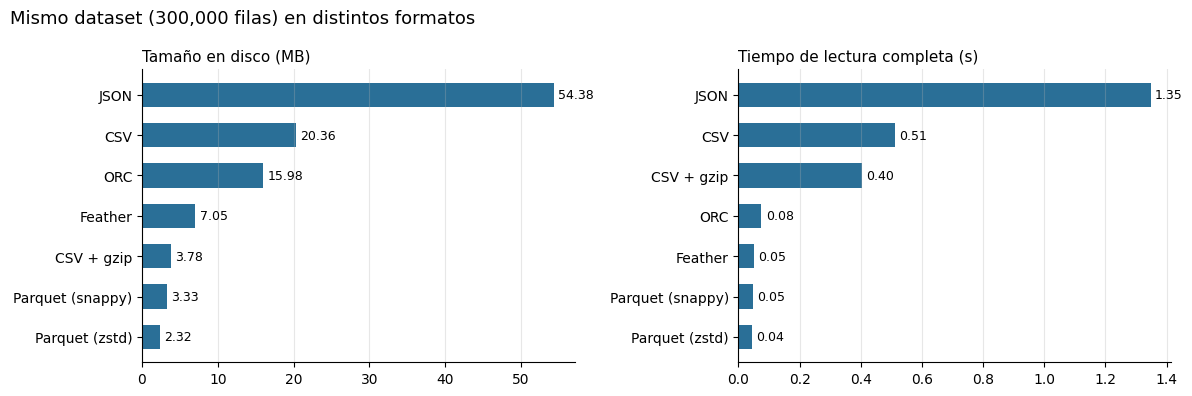

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, titulo in [(axes[0], "tamaño (MB)", "Tamaño en disco (MB)"), (axes[1], "lectura completa (s)", "Tiempo de lectura completa (s)")]:
    datos = comparacion[col].sort_values()
    ax.barh(datos.index, datos.values, color=COLOR, height=0.6)
    ax.bar_label(ax.containers[0], fmt="%.2f", padding=3, fontsize=9)
    ax.set_title(titulo, loc="left", fontsize=11)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", alpha=0.3)
fig.suptitle(f"Mismo dataset ({len(ordenes):,} filas) en distintos formatos", x=0.01, ha="left", fontsize=13)
plt.tight_layout()
plt.show()

**Interpretación:** los formatos columnares ocupan una fracción del CSV, se leen varias veces más rápido, conservan `datetime64`, `bool` y (Parquet/Feather) `category`, y permiten leer solo algunas columnas o filtrar filas antes de cargar. El CSV pierde los tipos (la fecha vuelve como texto `object`) y siempre se lee completo.

## 5. Automatización de ingesta (5 pts)

La ingesta manual (descargar un archivo, abrirlo en Excel, copiar/pegar, corregir a mano) **no es repetible, no deja rastro y no escala**. Al convertirla en un pipeline **ETL** (Extract → Transform → Load) con pandas y un orquestador se obtiene:

- **Resiliencia:** reintentos automáticos ante fallas de red, validación de esquema y calidad antes de cargar, registro (logging) y alertas; un archivo malo se aísla en cuarentena en lugar de detener todo.
- **Idempotencia:** volver a ejecutar el mismo día produce el mismo resultado (se sobrescribe la partición, no se duplica).
- **Escalabilidad:** lectura por bloques (`chunksize`), formatos columnares particionados, y paso natural a motores distribuidos (Spark, Dask, Polars, DuckDB) con la misma lógica.
- **Programación y trazabilidad:** orquestadores como **Apache Airflow, Prefect, Dagster**, Azure Data Factory, AWS Glue, o herramientas RPA/no-code (**Power Automate, n8n, Zapier**) ejecutan el script en horarios o eventos (llegada de un archivo, webhook) y guardan el historial de cada corrida.
- **Calidad gobernada:** reglas de validación (Great Expectations, Pandera) y control de versiones del código del pipeline (Git, CI/CD).

### 5.1 Mini pipeline ETL resiliente
Extrae de **varias fuentes con formatos distintos**, valida, transforma y carga a un Parquet **particionado por mes**. Una de las fuentes está corrupta a propósito para mostrar que el pipeline la aísla y continúa.

In [18]:
logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s", force=True)
log = logging.getLogger("etl")

ESQUEMA = {"id_orden": "int64", "fecha": "datetime64[ns]", "sucursal": "category", "servicio": "category", "monto": "float64"}

def extraer(ruta, reintentos=3, espera=1.0):
    for intento in range(1, reintentos + 1):
        try:
            return next(iter(leer_archivo(ruta).values()))
        except (OSError, requests.RequestException) as e:  # fallas transitorias: reintentar
            log.warning("Intento %d/%d falló para %s: %s", intento, reintentos, ruta, e)
            time.sleep(espera * intento)
    raise RuntimeError(f"No se pudo extraer {ruta}")

def validar(df, origen):
    faltantes = set(ESQUEMA) - set(df.columns)
    if faltantes:
        raise ValueError(f"{origen}: faltan columnas {sorted(faltantes)}")
    if df["id_orden"].duplicated().any():
        raise ValueError(f"{origen}: id_orden duplicados")

def transformar(df):
    df = df[list(ESQUEMA)].copy()
    df["fecha"] = pd.to_datetime(df["fecha"])
    df = df.astype(ESQUEMA)
    df = df[df["monto"] > 0]
    df["mes"] = df["fecha"].dt.strftime("%Y-%m")
    return df

def cargar(df, destino):
    df.to_parquet(destino, partition_cols=["mes"], existing_data_behavior="delete_matching")  # idempotente

def pipeline(fuentes, destino):
    ok, cuarentena = [], []
    for ruta in fuentes:
        try:
            df = extraer(ruta)
            validar(df, ruta.name)
            ok.append(transformar(df))
            log.info("OK  %-32s %7d filas", ruta.name, len(df))
        except Exception as e:
            cuarentena.append(ruta.name)
            log.error("CUARENTENA %s → %s", ruta.name, e)
    datos = pd.concat(ok).drop_duplicates("id_orden")
    cargar(datos, destino)
    log.info("Cargadas %d filas únicas en %s (%d particiones)", len(datos), destino, datos["mes"].nunique())
    return datos, cuarentena

fuentes = [GEN_DIR / f for f in ["ordenes_cp1252_puntoycoma.csv", "ordenes.json", "ordenes.xlsx",
                                  "ordenes_snappy.parquet", "ordenes_corrupto.csv"]]
destino = GEN_DIR / "lago" / "ordenes"
cargado, cuarentena = pipeline(fuentes, destino)

# Auto-verificación: idempotencia y resultado esperado
pipeline(fuentes, destino)
releido = pd.read_parquet(destino)
assert len(releido) == len(cargado) == N, "re-ejecutar no debe duplicar filas"
assert cuarentena == ["ordenes_corrupto.csv"]
print("Particiones:", sorted(p.name for p in destino.iterdir())[:4], "...")

2026-10-28 15:04:41,686 | INFO | OK  ordenes_cp1252_puntoycoma.csv       5000 filas
2026-10-28 15:04:41,735 | INFO | OK  ordenes.json                        2000 filas
2026-10-28 15:04:42,040 | INFO | OK  ordenes.xlsx                        2000 filas
2026-10-28 15:04:43,864 | INFO | OK  ordenes_snappy.parquet            300000 filas
/tmp/ipykernel_1567/2515270266.py:31: ParserWarning: Skipping line 3: expected 3 fields, saw 4

  df = pd.read_csv(ruta, sep=sep, encoding=enc, decimal=decimal, on_bad_lines="warn", **kw)
2026-10-28 15:04:43,870 | ERROR | CUARENTENA ordenes_corrupto.csv → ordenes_corrupto.csv: faltan columnas ['fecha', 'id_orden', 'sucursal']
2026-10-28 15:04:44,126 | INFO | Cargadas 300000 filas únicas en datos_generados/lago/ordenes (12 particiones)
2026-10-28 15:04:44,218 | INFO | OK  ordenes_cp1252_puntoycoma.csv       5000 filas
2026-10-28 15:04:44,273 | INFO | OK  ordenes.json                        2000 filas
2026-10-28 15:04:44,785 | INFO | OK  ordenes.xlsx        

Particiones: ['mes=2025-01', 'mes=2025-02', 'mes=2025-03', 'mes=2025-04'] ...


## 6. Importancia de los fundamentos (5 pts)

**Por qué se subestiman.** La carga de datos parece trivial: `pd.read_csv("archivo.csv")` funciona en el primer ejemplo del tutorial. Además, las herramientas modernas (notebooks, asistentes de IA, librerías AutoML) ocultan esta etapa, y el foco se va al modelo o al gráfico, que es lo visible. El costo aparece después y en silencio:

- **Errores silenciosos de tipos:** códigos postales o cédulas con ceros a la izquierda convertidos a enteros, fechas `03/04` leídas como marzo en lugar de abril, montos con coma decimal leídos como texto, `"N/D"` contado como categoría.
- **Codificación:** `Ã±` en lugar de `ñ`, o filas descartadas por `UnicodeDecodeError` que nadie nota.
- **Memoria y rendimiento:** cargar 20 columnas cuando se usan 3, o un CSV de 5 GB completo, revienta la RAM o el presupuesto de la nube.
- **Esquemas y nulos mal entendidos** generan joins que duplican filas o promedios sesgados.

**Por qué son un pilar en la era de la IA y la analítica.**
- *Garbage in, garbage out:* un modelo de IA o un dashboard es tan confiable como los datos que lo alimentan; la mayor parte del tiempo de un proyecto de datos se va en ingesta y preparación.
- Los **LLM y pipelines RAG** dependen de ingerir correctamente documentos JSON, HTML, PDF y tablas; el *feature engineering* y el entrenamiento se hacen en DataFrames y Parquet.
- Saber elegir formato, tipos y estrategia de carga es lo que separa un prototipo de un **sistema productivo**: reproducible, eficiente y auditable.
- Un desarrollador que entiende los fundamentos puede **verificar** el código que generan las herramientas de IA en lugar de aceptarlo a ciegas.

Ejemplo concreto de error silencioso:

In [19]:
crudo = io.StringIO("cedula,codigo,fecha,monto\n8-0123-04567,007,03/04/2025,\"1.250,50\"\n")
ingenuo = pd.read_csv(crudo)
crudo.seek(0)
correcto = pd.read_csv(crudo, dtype={"cedula": str, "codigo": str}, parse_dates=["fecha"], dayfirst=True,
                       decimal=",", thousands=".")
pd.DataFrame({"ingenuo": ingenuo.iloc[0].astype(str) + "  (" + ingenuo.dtypes.astype(str) + ")",
              "correcto": correcto.iloc[0].astype(str) + "  (" + correcto.dtypes.astype(str) + ")"})

,ingenuo,correcto
cedula,8-0123-04567 (object),8-0123-04567 (object)
codigo,7 (int64),007 (object)
fecha,03/04/2025 (object),2025-04-03 00:00:00 (datetime64[ns])
monto,"1.250,50 (object)",1250.5 (float64)


## 7. Comparativa técnica: Plotly vs. Matplotlib (15 pts)

| Criterio | Matplotlib | Plotly |
|---|---|---|
| **Salida** | Imagen estática (PNG, SVG, PDF) | HTML + JavaScript interactivo (zoom, pan, hover, selección); también PNG con `kaleido` |
| **Rendimiento con grandes volúmenes** | Rasteriza en el servidor: el tamaño del PNG no depende del número de puntos; maneja millones de puntos sin afectar al navegador | Envía los datos al navegador como JSON: con SVG se degrada desde ~10⁴–10⁵ puntos; `Scattergl` (WebGL) llega a ~10⁶. Para más, agregar o usar Datashader |
| **Personalización de diseño** | Control de bajo nivel de cada elemento (ejes, ticks, anotaciones, tipografía LaTeX); calidad de publicación | Temas y plantillas de alto nivel; layout declarativo; menos control fino, pero estética web moderna por defecto |
| **Interactividad / web** | Limitada (widgets, `mpld3`) | Nativa; con **Dash** se construyen tableros completos con filtros y callbacks |
| **Curva de aprendizaje** | API dual (pyplot vs. orientada a objetos) algo verbosa; muy documentada | `plotly.express` es muy rápida (una línea por gráfico); `graph_objects` y Dash requieren más aprendizaje |
| **Integración** | Reportes PDF, papers, notebooks, pruebas automáticas | Apps web, dashboards corporativos, notebooks, embebido en HTML |

**Decisión para un dashboard analítico en una aplicación web corporativa:**
- **Plotly (+ Dash)** cuando los usuarios necesitan **explorar** (hover con detalle, zoom en fechas, filtros, *drill-down*), el dashboard vive en el navegador y los datos que se envían están **agregados** (miles, no millones de puntos) o se usa WebGL.
- **Matplotlib** cuando el entregable es **estático** (reporte PDF, correo programado, imagen en un informe), se grafican **volúmenes masivos** que conviene rasterizar en el servidor, se requiere un control tipográfico fino, o el equipo ya domina la herramienta.
- En la práctica: Plotly para la capa interactiva del tablero, Matplotlib para reportes y procesos batch. En ambos casos se **agrega en pandas antes de graficar**.

### 7.1 Gráficas con Matplotlib (estáticas)

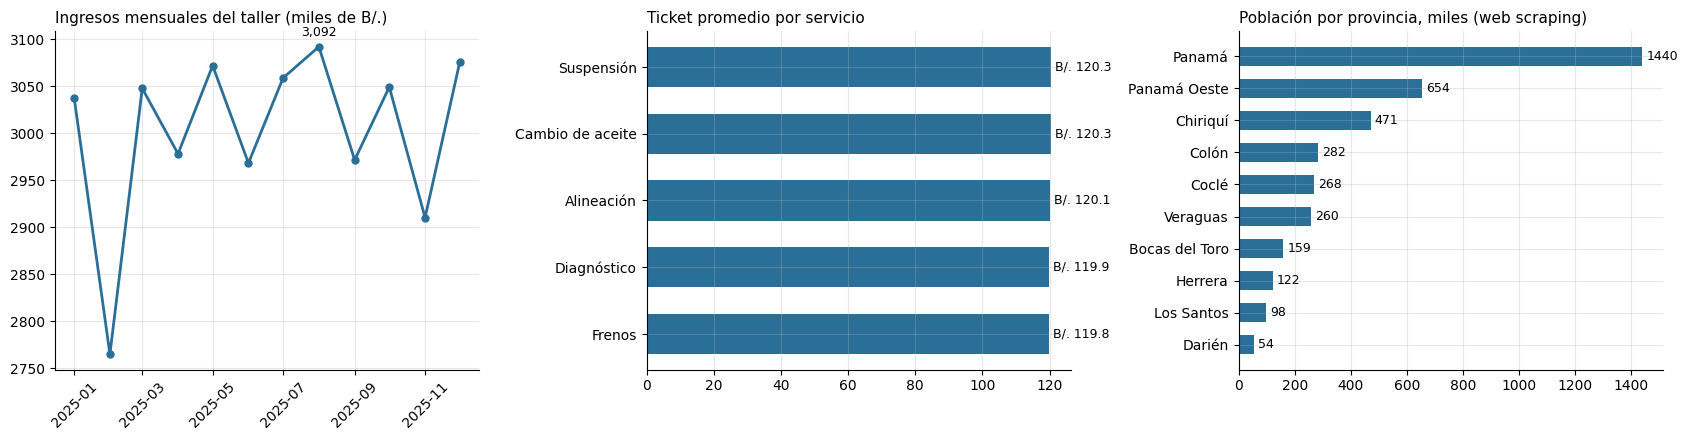

In [20]:
mensual = ordenes.set_index("fecha").resample("MS")["monto"].sum() / 1e3
por_servicio = ordenes.groupby("servicio", observed=True)["monto"].mean().sort_values()
pob = provincias.set_index("Provincia")["Población (2023)"].astype(float).sort_values() / 1e3

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

ax = axes[0]
ax.plot(mensual.index, mensual.values, color=COLOR, linewidth=2, marker="o", markersize=5)
ax.set_title("Ingresos mensuales del taller (miles de B/.)", loc="left", fontsize=11)
ax.annotate(f"{mensual.max():,.0f}", (mensual.idxmax(), mensual.max()), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
ax.tick_params(axis="x", rotation=45)

ax = axes[1]
ax.barh(por_servicio.index, por_servicio.values, color=COLOR, height=0.6)
ax.bar_label(ax.containers[0], fmt="B/. %.1f", padding=3, fontsize=9)
ax.set_title("Ticket promedio por servicio", loc="left", fontsize=11)

ax = axes[2]
ax.barh(pob.index, pob.values, color=COLOR, height=0.6)
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3, fontsize=9)
ax.set_title("Población por provincia, miles (web scraping)", loc="left", fontsize=11)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Render: 0.34 s | PNG: 227 KB


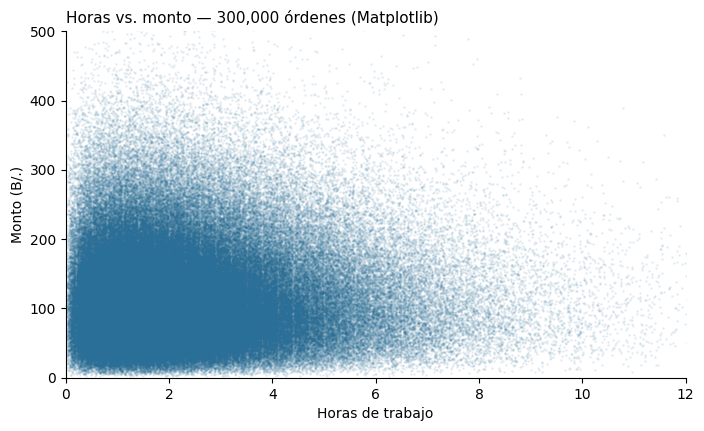

In [21]:
# Volumen masivo en Matplotlib: 300 000 puntos rasterizados → la imagen pesa lo mismo que con 300
fig, ax = plt.subplots(figsize=(8, 4.5))
t0 = time.perf_counter()
ax.scatter(ordenes["horas"], ordenes["monto"], s=1, alpha=0.08, color=COLOR, rasterized=True)
ax.set(xlabel="Horas de trabajo", ylabel="Monto (B/.)", xlim=(0, 12), ylim=(0, 500))
ax.set_title(f"Horas vs. monto — {len(ordenes):,} órdenes (Matplotlib)", loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
buf = io.BytesIO(); fig.savefig(buf, format="png", dpi=100)
print(f"Render: {time.perf_counter()-t0:.2f} s | PNG: {buf.tell()/1e3:.0f} KB")
plt.show()

### 7.2 Gráficas con Plotly (interactivas)
Pase el cursor sobre las barras/puntos, haga zoom arrastrando y doble clic para restablecer.

In [22]:
dash = make_subplots(rows=1, cols=3, subplot_titles=("Ingresos mensuales (miles de B/.)", "Ticket promedio por servicio",
                                                     "Población por provincia, miles (scraping)"), horizontal_spacing=0.12)
dash.add_trace(go.Scatter(x=mensual.index, y=mensual.values, mode="lines+markers", line=dict(color=COLOR, width=2),
                          marker=dict(size=8), hovertemplate="%{x|%b %Y}<br>B/. %{y:,.1f} mil<extra></extra>"), 1, 1)
dash.add_trace(go.Bar(x=por_servicio.values, y=por_servicio.index, orientation="h", marker_color=COLOR,
                      hovertemplate="%{y}<br>B/. %{x:.2f}<extra></extra>"), 1, 2)
dash.add_trace(go.Bar(x=pob.values, y=pob.index, orientation="h", marker_color=COLOR,
                      hovertemplate="%{y}<br>%{x:,.0f} mil hab.<extra></extra>"), 1, 3)
dash.update_layout(template="plotly_white", showlegend=False, height=450, title="Tablero del taller — Plotly")
dash.show()
dash.write_html("dashboard_plotly.html")  # se puede abrir o incrustar en una web

In [23]:
# Volumen grande en Plotly: WebGL (Scattergl) con una muestra de 50 000 puntos
muestra_g = ordenes.sample(50_000, random_state=1)
fig = px.scatter(muestra_g, x="horas", y="monto", render_mode="webgl", opacity=0.25,
                 hover_data=["sucursal", "servicio", "tecnico"], color_discrete_sequence=[COLOR],
                 title="Horas vs. monto — 50 000 órdenes (Plotly WebGL)", template="plotly_white",
                 labels={"horas": "Horas de trabajo", "monto": "Monto (B/.)"})
fig.update_traces(marker_size=3)
fig.update_layout(xaxis_range=[0, 12], yaxis_range=[0, 500], height=450)
fig.show()
print(f"Datos que viajan al navegador: ≈ {len(fig.to_json())/1e6:.1f} MB de JSON (vs. un PNG fijo en Matplotlib)")

Datos que viajan al navegador: ≈ 2.5 MB de JSON (vs. un PNG fijo en Matplotlib)


In [24]:
# Interactividad propia de Plotly: filtro desplegable por sucursal sin escribir JavaScript
serie = ordenes.groupby([pd.Grouper(key="fecha", freq="MS"), "sucursal"], observed=True)["monto"].sum().unstack() / 1e3
fig = go.Figure(go.Scatter(x=serie.index, y=serie.sum(axis=1), mode="lines+markers", line=dict(color=COLOR, width=2),
                           hovertemplate="%{x|%b %Y}<br>B/. %{y:,.1f} mil<extra></extra>"))
botones = [dict(label="Todas", method="restyle", args=[{"y": [serie.sum(axis=1)]}])] + \
          [dict(label=s, method="restyle", args=[{"y": [serie[s]]}]) for s in serie.columns]
fig.update_layout(template="plotly_white", height=420, title="Ingresos mensuales por sucursal (miles de B/.)",
                  updatemenus=[dict(buttons=botones, x=1, xanchor="right", y=1.15)])
fig.show()

## Conclusiones

1. El **DataFrame** es la abstracción central: columnar, tipada por columna, vectorizada y con semántica relacional; superó en el experimento a la lista de diccionarios tanto en tiempo como en memoria.
2. Con un **lector universal** basado en `read_csv`, `read_excel`, `read_json`, `read_xml`, `read_sql`, `read_parquet`, `read_orc`, `read_feather`, `read_pickle` y `read_html` se cargaron todos los archivos, resolviendo automáticamente **encoding** y **separador**; los archivos grandes se procesaron con `chunksize`, `usecols`, `dtype` y `engine="pyarrow"`, y se realizó **web scraping** de Wikipedia.
3. Los **formatos columnares** (Parquet, Feather, ORC) redujeron el tamaño y el tiempo de lectura frente al CSV, conservaron los tipos y permitieron proyección de columnas y filtros (*predicate pushdown*).
4. Un **pipeline ETL** con validación, cuarentena, reintentos e idempotencia convierte la ingesta manual en un proceso automatizable y escalable.
5. **Matplotlib** es la opción para salidas estáticas y volúmenes masivos; **Plotly** para tableros web interactivos con datos agregados.

## Referencias
- pandas development team. *IO tools (text, CSV, HDF5, …)* — pandas 3.0 documentation. https://pandas.pydata.org/docs/user_guide/io.html
- pandas development team. *Scaling to large datasets*. https://pandas.pydata.org/docs/user_guide/scale.html
- McKinney, W. (2022). *Python for Data Analysis* (3.ª ed.). O'Reilly.
- Apache Parquet Documentation. https://parquet.apache.org/docs/
- Apache ORC Specification. https://orc.apache.org/specification/
- Apache Arrow — Feather File Format. https://arrow.apache.org/docs/python/feather.html
- Plotly Python Documentation. https://plotly.com/python/ · Matplotlib Documentation. https://matplotlib.org/stable/